# Task 1: Three-family information coverage

## tl;dr

Executed on 2026-11-18. Fixed OLS using only temperature, RH and rainfall achieved 2023–2025 MSE skills of **62.47–67.60% for sunshine**, **34.21–46.80% for cloud**, and **12.08–17.90% for wind**, relative to seasonal-only estimates. All nine primary three-family skill CIs were above zero.

In 2024, full inputs improved wind/cloud skill by **3.14/2.69 percentage points**; both paired CIs excluded zero with 7- and 14-day blocks. 2025 point estimates were close, without a prespecified equivalence margin. This supports partial observation information coverage, not complete representation, forecast equivalence, causal importance or social ranking.

Full numerical interpretation and rerun instructions: [results report](../../FINDINGS_ZH.md).

## Context & Methods

RQ: How much same-day information about wind/cloud/sunshine can the three selected families reconstruct, and what is lost relative to full inputs?

Primary estimator is fixed OLS, without F-based filtering. LASSO (40 alphas, three chronological inner folds, one-SE) and Bayesian BMA are sensitivity analyses. Shared implementations are in `research/task1_variable_selection.ipynb`; the experiment and export code is in `scripts/task1_three_family_representation.py`.

### Key Assumptions

- Same 1,458 complete dates; no imputation or station substitution. Rainfall input uses log1p(mm), Trace .025 with 0/.05 sensitivity.
- Two annual Fourier harmonics, training-only preprocessing; expanding train periods and 2023/24/25 evaluation, seven calendar days purged.
- Entire outcome family excluded, including cloud/sunshine jointly. Three-family = Tmax/Tmin/RH min/RH max/rainfall.
- Bayesian scopes share the full-model training AR(1) estimate to isolate predictor scope; g/n .25/1/4 and inclusion prior .25/.5.
- Paired circular calendar-block bootstrap (7/14 days, 1,000 draws), conditional on fitted models. Positive skill gap = information loss from restricting inputs. No equivalence margin or pass/fail threshold is imposed.
- Exploratory: 2025 and the three-family choice were already explored. These are finite station proxies, not territory PSR truth or full weather descriptions.

Traceability: Task 1 scope justification -> three-family coverage RQ -> frozen daily observations -> paired temporal reconstruction -> code/exports -> station/model limits -> bounded selection rationale.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'requirements-variable-selection.txt').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
import task1_three_family_representation as experiment
from IPython.display import display, Image
SYNTHETIC = False
N_ALPHA = 40
N_BOOTSTRAP = 1000

## Data

Read-only frozen inputs: `data/derived/task1_variable_selection_20261117/inputs`. Input hashes, QC, stations and units are verified before fitting. No database connection or GPU is needed.

In [2]:
methods = experiment.notebook_methods()
long, input_manifest, catalog = methods.synthetic_input() if SYNTHETIC else methods.load_frozen(experiment.INPUT)
wide, coverage = methods.prepare_panel(long, .025)
print('Rows:', len(long), 'Common complete dates:', int(wide.notna().all(axis=1).sum()))
display(coverage[['year', 'channel', 'usable_days', 'common_days', 'station', 'unit']])

Rows: 11688 Common complete dates: 1458


,year,channel,usable_days,common_days,station,unit
0,2022,tmax,365,365,Hong Kong Observatory,°C
1,2022,tmin,365,365,Hong Kong Observatory,°C
2,2022,rh_min,365,365,Hong Kong Observatory,%
3,2022,rh_max,365,365,Hong Kong Observatory,%
4,2022,rainfall,365,365,Hong Kong Observatory,mm
5,2022,wind_speed,365,365,Hong Kong International Airport,km/h
6,2022,cloud,365,365,Hong Kong Observatory,%
7,2022,sunshine,365,365,King's Park,hours
8,2023,tmax,365,362,Hong Kong Observatory,°C
9,2023,tmin,365,362,Hong Kong Observatory,°C


## Results

Fixed OLS is the primary comparison; LASSO and BMA test whether the conclusion depends on selection/shrinkage. Every result is saved, including prior/Trace/block sensitivities and negative skills/gaps.

In [3]:
run_dir, results = experiment.execute(SYNTHETIC, N_ALPHA, N_BOOTSTRAP)
from test_task1_three_family_representation import verify_run
validation = verify_run(run_dir)
print(validation)
primary = results['comparison'].query("scenario=='primary' and method=='ols' and block_calendar_days==7")
display(primary[['evaluation_year','target','n_test','three_family_skill','full_skill','skill_gap','skill_gap_ci_low','skill_gap_ci_high']].round(4))
print('Returnable ZIP:', run_dir.with_suffix('.zip'))

primary: 2023
primary: 2024
primary: 2025
trace_lower: 2023
trace_lower: 2024
trace_lower: 2025
trace_upper: 2023
trace_upper: 2024
trace_upper: 2025
Results: [workspace]\data\derived\task1_three_family_representation_20261118\results\20261118T065444356823Z
{'manifest_hashes_verified': 15, 'prediction_rows': 157392, 'metric_rows': 432, 'model_statuses': 432, 'max_mse_recompute_error': 4.547473508864641e-13, 'lasso_failed_alphas': 0, 'all_checks_passed': True}
Returnable ZIP: [workspace]\data\derived\task1_three_family_representation_20261118\results\20261118T065444356823Z.zip


Fallback to a different backend


,evaluation_year,target,n_test,three_family_skill,full_skill,skill_gap,skill_gap_ci_low,skill_gap_ci_high
14,2023,wind_speed,362,0.1575,0.1055,-0.0520,-0.1101,-0.0014
30,2023,cloud,362,0.4680,0.4506,-0.0174,-0.0401,0.0034
46,2023,sunshine,362,0.6609,0.6549,-0.0059,-0.0172,0.0062
62,2024,wind_speed,366,0.1208,0.1522,0.0314,0.0056,0.0580
78,2024,cloud,366,0.3422,0.3691,0.0269,0.0036,0.0561
94,2024,sunshine,366,0.6759,0.6758,-0.0001,-0.0064,0.0068
110,2025,wind_speed,365,0.1790,0.1786,-0.0004,-0.0249,0.0225
126,2025,cloud,365,0.3517,0.3498,-0.0019,-0.0238,0.0166
142,2025,sunshine,365,0.6247,0.6230,-0.0017,-0.0079,0.0045


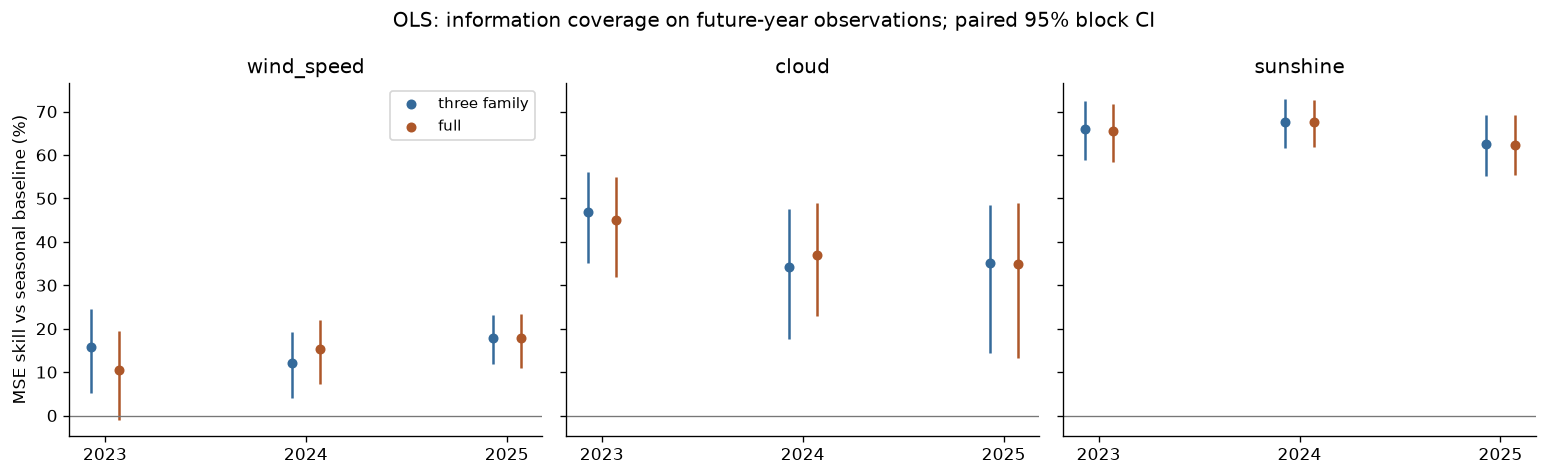

In [4]:
display(Image(filename=str(run_dir/'ols_skill.png')))

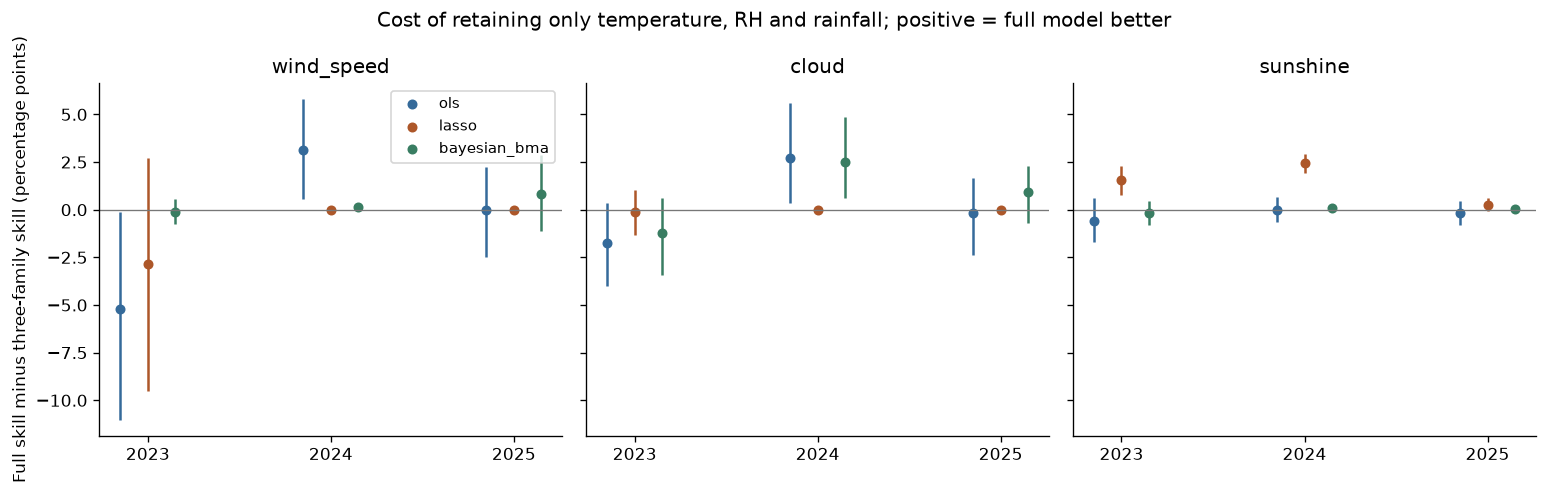

In [5]:
display(Image(filename=str(run_dir/'paired_skill_gap.png')))

## Takeaways

- Sunshine/cloud contain substantial reconstructible information associated with the three retained families. Wind reconstruction remains limited.
- Additional families still helped wind/cloud in 2024; close 2025 estimates do not prove equivalence.
- Method differences matter: LASSO wind fell back to seasonal-only in 2024/25; LASSO sunshine improved with full inputs in 2023/24, unlike the OLS point estimates.
- Trace sensitivity was small for primary OLS gaps (<0.015 percentage points). 2023 OLS wind superiority was not robust to 14-day blocks.
- Three-family scope has an empirical information-coverage rationale, while omitted weather products still require separate forecast verification.

432 model statuses and 432 paired comparison summaries passed export validation. Code, fixed inputs, settings, versions, predictions and source hashes are retained. CI conditions on fitted models; 2025 was already explored. See the dated report for station/proxy and model limits.